In [1]:
import pandas as pd

design_dir = '../../design_pipeline/MAGE-A3/'
df = pd.read_csv(f'{design_dir}/MAGE-A3_cdr3_generation.csv')
df['Pred'] = pd.read_csv(f'{design_dir}/MAGE-A3_cdr3_generation_binding/predictions.csv')['Pred']
bg_pred = pd.read_csv(f'{design_dir}/sampled_bg_df_binding/predictions.csv')['Pred']


In [2]:
# Compute percentiles of CDR3 designs compared to background predictions
from scipy import stats

# Calculate percentiles for each CDR3 design prediction compared to background
percentiles = []
for pred in df['Pred']:
    percentile = stats.percentileofscore(bg_pred, pred)
    percentiles.append(percentile)

df['Percentile'] = percentiles

# Display top designs by percentile (higher percentile = better than background)
print("Top 10 designs by percentile:")
print(df.nlargest(10, 'Percentile')[['CDR3A', 'CDR3B', 'Pred', 'Percentile']])

# Display summary statistics
print(f"\nSummary statistics:")
print(f"Mean percentile: {df['Percentile'].mean():.2f}")
print(f"Median percentile: {df['Percentile'].median():.2f}")
print(f"Max percentile: {df['Percentile'].max():.2f}")
print(f"Min percentile: {df['Percentile'].min():.2f}")

# Count designs above different percentile thresholds
print(f"\nDesigns above percentile thresholds:")
print(f"Above 90th percentile: {(df['Percentile'] > 90).sum()}")
print(f"Above 95th percentile: {(df['Percentile'] > 95).sum()}")
print(f"Above 99th percentile: {(df['Percentile'] > 99).sum()}")

df_on_target = df

Top 10 designs by percentile:
               CDR3A          CDR3B      Pred  Percentile
483  CAVVNYGGSQGNLIF  CASSWANSYEQYF  0.774552       99.93
673  CAVPHYGGSQGNLIF  CASSWGGSYEQYF  0.738766       99.91
265  CAVQNYGGSQGNLIF  CASSLAGTYEQYF  0.673774       99.85
932  CAVPNYGGSQGNLIF  CASSWGGAYEQYF  0.673200       99.85
656  CAVMNYGGSQGNLIF  CASSWAGSYEQYF  0.659618       99.84
684  CAVPNYGGSQDNLIF  CASSLAGTYEQYF  0.584165       99.57
202  CAVRPSGGANYQLTF  CASSYGSGYEYTF  0.486092       99.02
740  CAVWNYGGSQGNLIF  CASSWDGNTEAFF  0.480019       98.98
436  CAVPNSGGSNYKLTF  CASSFASGQGQHF  0.476786       98.92
665  CAVRGASGGYQKLTF  CASSWGNSYEQYF  0.466618       98.85

Summary statistics:
Mean percentile: 52.64
Median percentile: 51.58
Max percentile: 99.93
Min percentile: 1.02

Designs above percentile thresholds:
Above 90th percentile: 82
Above 95th percentile: 38
Above 99th percentile: 7


In [3]:
off_target_peptide = 'ESDPIVAQY'
df = pd.read_csv(f'{design_dir}/MAGE-A3_cdr3_generation_{off_target_peptide}.csv')
df['Pred'] = pd.read_csv(f'{design_dir}/MAGE-A3_cdr3_generation_{off_target_peptide}_binding/predictions.csv')['Pred']
bg_pred = pd.read_csv(f'{design_dir}/sampled_bg_df_{off_target_peptide}_binding/predictions.csv')['Pred']

# Compute percentiles of CDR3 designs compared to background predictions
from scipy import stats

# Calculate percentiles for each CDR3 design prediction compared to background
percentiles = []
for pred in df['Pred']:
    percentile = stats.percentileofscore(bg_pred, pred)
    percentiles.append(percentile)

df['Percentile'] = percentiles

# Display top designs by percentile (higher percentile = better than background)
print("Top 10 designs by percentile:")
print(df.nlargest(10, 'Percentile')[['CDR3A', 'CDR3B', 'Pred', 'Percentile']])

# Display summary statistics
print(f"\nSummary statistics:")
print(f"Mean percentile: {df['Percentile'].mean():.2f}")
print(f"Median percentile: {df['Percentile'].median():.2f}")
print(f"Max percentile: {df['Percentile'].max():.2f}")
print(f"Min percentile: {df['Percentile'].min():.2f}")

# Count designs above different percentile thresholds
print(f"\nDesigns above percentile thresholds:")
print(f"Above 90th percentile: {(df['Percentile'] > 90).sum()}")
print(f"Above 95th percentile: {(df['Percentile'] > 95).sum()}")
print(f"Above 99th percentile: {(df['Percentile'] > 99).sum()}")

df_off_target = df

Top 10 designs by percentile:
               CDR3A          CDR3B      Pred  Percentile
508  CAVRFSSGSAQQLTF  CASSWDSTYEQYF  0.598880       99.63
483  CAVVNYGGSQGNLIF  CASSWANSYEQYF  0.583578       99.48
673  CAVPHYGGSQGNLIF  CASSWGGSYEQYF  0.545748       99.23
597  CAVPFYGGATNKLIF  CASSWGSSYEQYF  0.512908       98.92
684  CAVPNYGGSQDNLIF  CASSLAGTYEQYF  0.483991       98.48
656  CAVMNYGGSQGNLIF  CASSWAGSYEQYF  0.469457       98.19
576  CAVPFSSGSARQLTF  CASSWDNSYEQYF  0.443194       97.65
588  CAVRPRPTNAGKSTF  CASSPDGYYGYTF  0.442561       97.65
265  CAVQNYGGSQGNLIF  CASSLAGTYEQYF  0.440471       97.61
765  CAVRPGKSSGDKLTF  CASIGDNSYEQYF  0.440789       97.61

Summary statistics:
Mean percentile: 43.72
Median percentile: 41.86
Max percentile: 99.63
Min percentile: 0.02

Designs above percentile thresholds:
Above 90th percentile: 48
Above 95th percentile: 22
Above 99th percentile: 3


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['axes.labelsize'] = 11
mpl.rcParams['axes.titlesize'] = 12
mpl.rcParams['legend.title_fontsize'] = 10
mpl.rcParams['legend.fontsize'] = 10
mpl.rcParams['xtick.labelsize'] = 10
mpl.rcParams['ytick.labelsize'] = 10

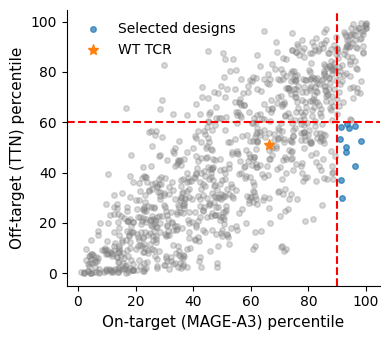

In [5]:
plt.figure(figsize=(4, 3.5))

mask = (df_on_target['Percentile'] >= 90) & (df_off_target['Percentile'] <= 60)
plt.plot(df_on_target['Percentile'][~mask], df_off_target['Percentile'][~mask], 'o', alpha=0.3, markersize=4, c='gray', rasterized=True)
plt.plot(df_on_target['Percentile'][mask], df_off_target['Percentile'][mask], 'o', alpha=0.7, markersize=4, label='Selected designs')
plt.plot(df_on_target['Percentile'].iloc[-1], df_off_target['Percentile'].iloc[-1], '*', markersize=8, label='WT TCR')
plt.xticks(range(0, 101, 20))
plt.yticks(range(0, 101, 20))
plt.axhline(y=60, color='r', linestyle='--')
plt.axvline(x=90, color='r', linestyle='--')
plt.xlabel('On-target (MAGE-A3) percentile')
plt.ylabel('Off-target (TTN) percentile')
plt.legend(frameon=False)

sns.despine()
plt.tight_layout()
# plt.savefig('MAGE_on_target_off_target_percentile_tcrdiff.pdf', dpi=300, backend='pdf')
plt.show()

In [6]:
# select TCRs with high on-target percentile and low off-target percentile

df_on_target.rename(columns={'Percentile': 'On target percentile'}, inplace=True)
df_on_target['Off target percentile'] = df_off_target['Percentile']

selected_tcr = df_on_target[(df_on_target['On target percentile'] >= 90) & (df_on_target['Off target percentile'] <= 60)]
# selected_tcr.to_csv('MAGE_selected_tcr.csv')
selected_tcr.drop_duplicates(subset=['CDR3A', 'CDR3B'])

,CDR3A,CDR3B,Peptide,MHC,MHCA,MHCB,TRAV,TRBV,Organism,Pred,On target percentile,Off target percentile
128,CAVRPSNFANEKLTF,CASSLDGRDGYTF,EVDPIGHLY,HLA-A*01:01,A*01:01,b2m,TRAV21*01,TRBV5-1*01,human,0.220928,91.68,30.08
263,CAVPNSGTGADGLTF,CASSWGLDNEQFF,EVDPIGHLY,HLA-A*01:01,A*01:01,b2m,TRAV21*01,TRBV5-1*01,human,0.238115,92.96,48.04
386,CAVGEFGGGSEKFTF,CASSLGGGYEQYF,EVDPIGHLY,HLA-A*01:01,A*01:01,b2m,TRAV21*01,TRBV5-1*01,human,0.250346,93.51,59.24
398,CAVRGSNFGNEKLTF,CASSLAGDYGYTF,EVDPIGHLY,HLA-A*01:01,A*01:01,b2m,TRAV21*01,TRBV5-1*01,human,0.433676,98.44,52.54
465,CAVPNSGGSNYKLTF,CASSLAGNYGYTF,EVDPIGHLY,HLA-A*01:01,A*01:01,b2m,TRAV21*01,TRBV5-1*01,human,0.216015,91.42,36.89
530,CAVRPFKAAGNKLTF,CASSWGGDQPQHF,EVDPIGHLY,HLA-A*01:01,A*01:01,b2m,TRAV21*01,TRBV5-1*01,human,0.240003,93.08,50.05
538,CAVRGYSGANSKLTF,CASSWGNSYEQYF,EVDPIGHLY,HLA-A*01:01,A*01:01,b2m,TRAV21*01,TRBV5-1*01,human,0.217942,91.50,58.23
709,CAVMNSGGGADGLTF,CASSWGADQPQHF,EVDPIGHLY,HLA-A*01:01,A*01:01,b2m,TRAV21*01,TRBV5-1*01,human,0.260770,93.98,57.71
791,CAVDLMKTSYGKLIF,CASRPDGGYGYTF,EVDPIGHLY,HLA-A*01:01,A*01:01,b2m,TRAV21*01,TRBV5-1*01,human,0.211343,90.99,53.54
798,CAVNPSNFGNERLTF,CASSLGGSYEYTF,EVDPIGHLY,HLA-A*01:01,A*01:01,b2m,TRAV21*01,TRBV5-1*01,human,0.322026,96.24,42.74
